# Step 18 — Barotropic Quasi-Geostrophic Flow: the Double Gyre

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step18_barotropic_qg.ipynb)

*The last of the rotating shallow-water series; moved from somax's tutorial series.*

[Step 17](step17_shallow_water_2d.ipynb) spun up a double gyre with the shallow-water equations, and its time step had to follow the gravity waves. Quasi-geostrophic flow has none: one scalar, the potential vorticity, carries the slow balanced motion, and a Poisson solve gives the streamfunction back from it. The same gyres take a time step some twenty times longer.

**What you'll learn:**

1. How to run [`BarotropicQG`](xref:api#sesmax_ocean.qg.BarotropicQG) under a wind-stress curl
2. What the PV inversion and the Arakawa Jacobian do, and which quantities the second conserves
3. How the interior compares with Sverdrup balance
4. How to differentiate a run with respect to the wind and the viscosity

## Setup

On Colab, install `sesmax-ocean`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    repository = "git+https://github.com/jejjohnson/sesmax@main#subdirectory=packages/"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            f"sesmax-core @ {repository}sesmax-core",
            f"sesmax-ocean @ {repository}sesmax-ocean",
        ],
        check=True,
    )

## The PDE

The barotropic quasi-geostrophic equation advects the potential vorticity anomaly $q$ and the planetary vorticity $\beta y$ with the flow of a streamfunction $\psi$:

$$
\frac{\partial q}{\partial t} + J(\psi, q + \beta y) = -\tau_0 \sin\left(\frac{2 \pi y}{L_y}\right) - \kappa \nabla^2 \psi + \nu \nabla^2 q, \qquad \nabla^2 \psi = q
$$

with the Jacobian $J(\psi, q) = \partial_x \psi \, \partial_y q - \partial_y \psi \, \partial_x q$ and the velocity $u = -\partial_y \psi$, $v = \partial_x \psi$. The walls are streamlines, $\psi = 0$, and $q = 0$ on them.

Every tendency needs one Poisson solve, which a discrete sine transform does exactly in this closed box. Arakawa's form of the Jacobian conserves the energy $\frac{1}{2} \int |\nabla \psi|^2$, so the nonlinear term alone can neither create nor destroy it, and conserves the enstrophy up to what happens at the walls.

Away from the walls the wind's curl balances the advection of planetary vorticity:

$$
\beta v_S = -\tau_0 \sin\left(\frac{2 \pi y}{L_y}\right)
$$

The return flow is a western boundary current as wide as the Munk width $\delta_M = (\nu / \beta)^{1/3}$, or the Stommel width $\delta_S = \kappa / \beta$ if that is larger.

### Symbols

The page is dimensional, in SI units.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $(x, y)$ | spatial coordinates (m) | $\mathbb{R}^2$ |
| $t$ | time (s) | $\mathbb{R}$ |
| $q(x, y, t)$ | potential vorticity anomaly (1/s) | $\mathbb{R}$ |
| $\psi(x, y, t)$ | streamfunction (m²/s) | $\mathbb{R}$ |
| $u$, $v$ | velocity components (m/s) | $\mathbb{R}$ |
| $J(\cdot, \cdot)$ | Jacobian | $\mathbb{R}$ |
| $\beta$ | meridional gradient of the Coriolis parameter (1/(m s)) | $\mathbb{R}_{>0}$ |
| $\tau_0$ | amplitude of the wind's curl (1/s²) | $\mathbb{R}_{>0}$ |
| $\nu$, $\kappa$ | viscosity (m²/s) and bottom drag (1/s) | $\mathbb{R}_{>0}$ |
| $v_S(y)$ | Sverdrup velocity (m/s) | $\mathbb{R}$ |
| $\delta_M$, $\delta_S$ | Munk and Stommel widths (m) | $\mathbb{R}_{>0}$ |
| $L_x$, $L_y$ | domain lengths (m) | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$, $N_T$ | number of interior cells along $x$ and $y$, and of saved snapshots | count |
| $\Delta x$, $\Delta t$ | grid spacing (m) and time step (s) | $\mathbb{R}_{>0}$ |

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from sesmax_ocean.eval import qg_balance_residual
from sesmax_ocean.qg import BarotropicQG, BarotropicQGState
from sesmax_ocean.resolution import check_munk_width

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,equinox,diffrax,sesmax_core,sesmax_ocean"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax         : 0.12.0.1
equinox     : 0.13.8
diffrax     : 0.7.2
sesmax_core : 0.3.1
sesmax_ocean: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

A square basin of 1000 km, with a viscosity that puts four cells across the Munk layer, so that [`check_munk_width`](xref:api#sesmax_ocean.resolution.check_munk_width) passes without a warning.

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 64 interior cells

num_cells = 64
domain_length = 1.0e6
beta = 1.6e-11
viscosity = 4.0e3
drag = 1.0e-7
wind = 1.0e-12


def double_gyre(**overrides):
    parameters = {
        "lateral_viscosity": viscosity,
        "bottom_drag": drag,
        "wind_amplitude": wind,
    }
    # today (sesmax_ocean)
    return BarotropicQG.create(
        nx=num_cells,
        ny=num_cells,
        Lx=domain_length,
        Ly=domain_length,
        f0=1.0e-4,
        beta=beta,
        wind_profile="doublegyre",
        **(parameters | overrides),
    )


model = double_gyre()
spacing = model.grid.spacing("x")
# δ_M = (ν / β)^(1/3)
munk_width = (viscosity / beta) ** (1.0 / 3.0)
# δ_S = κ / β
stommel_width = drag / beta
print(f"Grid spacing:  {spacing / 1e3:.1f} km")
print(f"Munk width:    {munk_width / 1e3:.1f} km")
print(f"Stommel width: {stommel_width / 1e3:.1f} km")

# today (sesmax_ocean): passes without a word
check_munk_width(None, model)

Grid spacing:  15.6 km
Munk width:    63.0 km
Stommel width: 6.2 km


## 2. Forward simulation

From rest, for about 230 days. The states the integrator returns have their ghost cells filled, so we can compute diagnostics of them.

In [5]:
# Shapes: N_T = 100 saved snapshots; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# today (sesmax_ocean)
at_rest = BarotropicQGState(q=jnp.zeros(model.grid.shape))  # q → G

end_time = 2.0e7
time_step = 2000.0
# tₖ = k t₁ / (N_T − 1)
save_times = jnp.linspace(0.0, end_time, 100)  # → (N_T,)

# today (sesmax_core, diffrax)
solution = model.integrate(  # q → N_T × G
    at_rest,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
    max_steps=50_000,
)
# today (sesmax_ocean): the diagnostics of each snapshot
states = solution.ys
diagnostics = jax.vmap(model.diagnose)(states)

spun_up = jax.tree.map(lambda field: field[-1], states)
largest_v = jnp.max(jnp.abs(diagnostics.v[-1]))  # → ()
# today (sesmax_ocean): ‖∇²ψ − q‖ / ‖q‖
residual = qg_balance_residual(model, spun_up)  # → ()
print(f"All finite: {bool(jnp.all(jnp.isfinite(states.q)))}")
print(f"Largest |v|: {float(largest_v):.2f} m/s")
print(f"Residual of the PV inversion: {float(residual):.0e}")

All finite: True
Largest |v|: 0.44 m/s
Residual of the PV inversion: 2e-05


## 3. The gyres

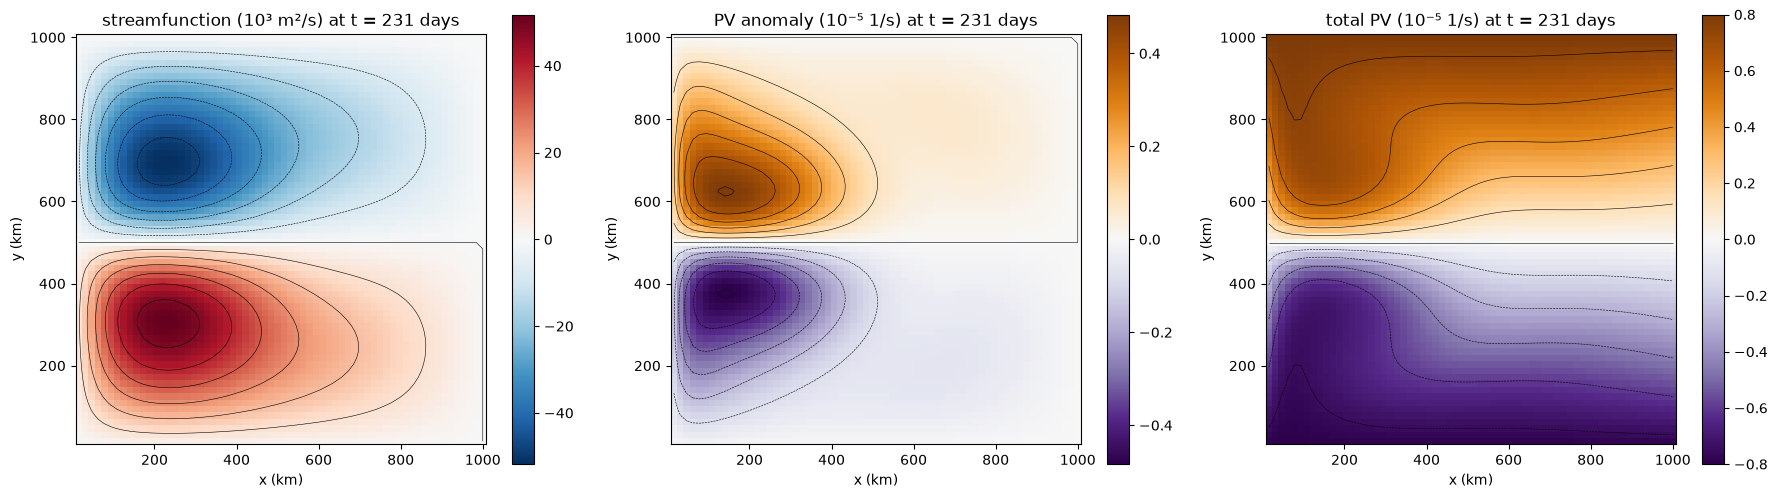

In [6]:
# Shapes: N_Ωx,x = 64 columns; N_Ωx,y = 64 rows

inner = slice(1, -1)
interior = (inner, inner)
# xᵢ = i Δx, yⱼ = j Δy
x_position = jnp.arange(model.grid.Nx) * spacing  # → (N_Ωx,x + 2,)
y_position = jnp.arange(model.grid.Ny) * spacing  # → (N_Ωx,y + 2,)
x_km = x_position[inner] / 1e3
y_km = y_position[inner] / 1e3

# qₐ = q + β (y − L_y / 2)
planetary = beta * (y_position - domain_length / 2.0)  # → (N_Ωx,y + 2,)
total_vorticity = einx.add("y x, y -> y x", spun_up.q, planetary)  # → G

panels = [
    (diagnostics.psi[-1][interior] / 1e3, "RdBu_r", "streamfunction (10³ m²/s)"),
    (spun_up.q[interior] * 1e5, "PuOr_r", "PV anomaly (10⁻⁵ 1/s)"),
    (total_vorticity[interior] * 1e5, "PuOr_r", "total PV (10⁻⁵ 1/s)"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (field, colours, label) in zip(axes, panels, strict=True):
    largest = float(jnp.max(jnp.abs(field)))
    mesh = ax.pcolormesh(
        x_km, y_km, field, cmap=colours, vmin=-largest, vmax=largest, shading="auto"
    )
    ax.contour(x_km, y_km, field, levels=12, colors="k", linewidths=0.4)
    ax.set_title(f"{label} at t = {end_time / 86400.0:.0f} days")
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.set_aspect("equal")
    plt.colorbar(mesh, ax=ax)
plt.tight_layout()
plt.show()

## 4. The boundary current and the interior

A section of $v$ across each gyre, where the wind's curl is strongest, with the Sverdrup velocity of that latitude. On the right, the mean kinetic energy while the gyres spin up.

southern gyre: boundary current +0.41 m/s, eastern half -0.054 m/s, Sverdrup -0.062 m/s
northern gyre: boundary current -0.41 m/s, eastern half +0.054 m/s, Sverdrup +0.062 m/s


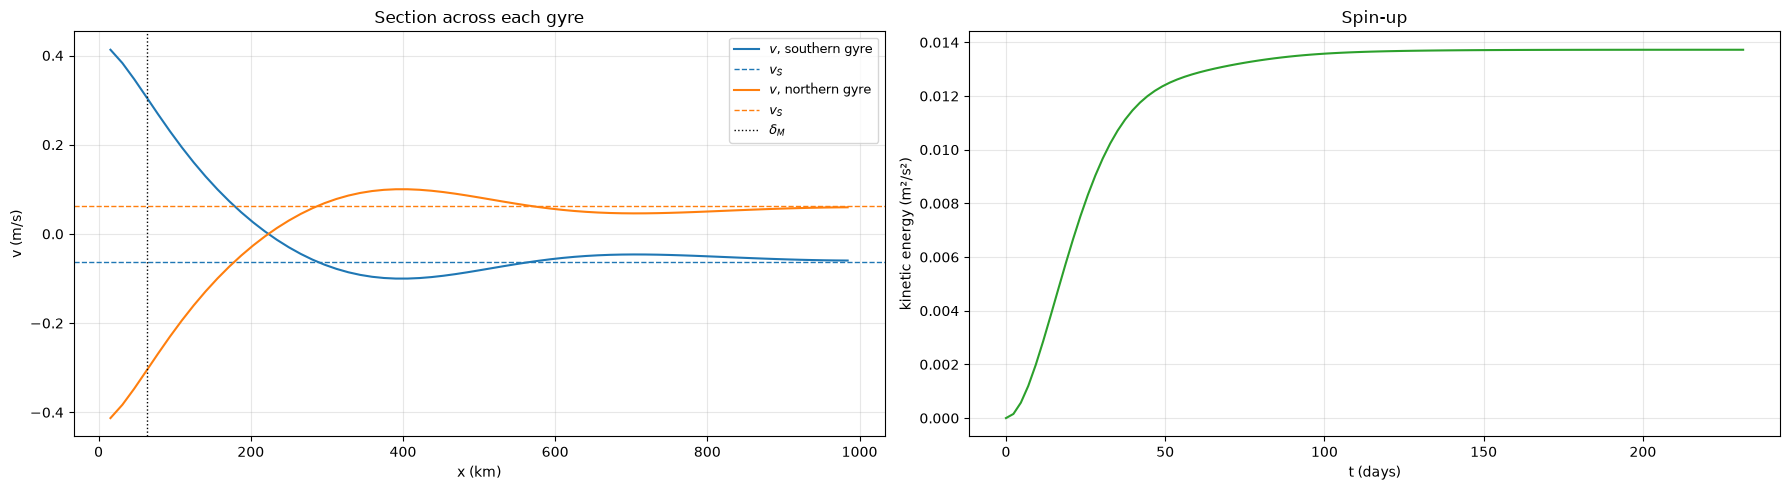

In [7]:
# Shapes: N_Ωx,x = 64 columns; N_T = 100 saved snapshots

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fractions = {"southern gyre": 0.25, "northern gyre": 0.75}
for index, (name, fraction) in enumerate(fractions.items()):
    row = round(fraction * num_cells)
    section = diagnostics.v[-1][row, 1:-2]  # → (N_Ωx,x − 1,), off the eastern wall
    # v_S = −(τ₀ / β) sin(2π y / L_y)
    sverdrup = -wind / beta * jnp.sin(2.0 * jnp.pi * y_position[row] / domain_length)
    axes[0].plot(x_km[:-1], section, color=f"C{index}", label=f"$v$, {name}")
    axes[0].axhline(sverdrup, color=f"C{index}", ls="--", lw=1.0, label="$v_S$")
    # the eastern half of the basin, off both walls
    middle = section[num_cells // 2 : -3]  # → (N_Ωx,x / 2 − 4,)
    mean_middle = einx.mean("[x] ->", middle)  # → ()
    print(
        f"{name}: boundary current {float(section[0]):+.2f} m/s, "
        f"eastern half {float(mean_middle):+.3f} m/s, "
        f"Sverdrup {float(sverdrup):+.3f} m/s"
    )
axes[0].axvline(munk_width / 1e3, color="k", ls=":", lw=1.0, label=r"$\delta_M$")
axes[0].set_xlabel("x (km)")
axes[0].set_ylabel("v (m/s)")
axes[0].set_title("Section across each gyre")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

mean_kinetic = diagnostics.kinetic_energy / domain_length**2  # → (N_T,)
axes[1].plot(save_times / 86400.0, mean_kinetic, color="C2")
axes[1].set_xlabel("t (days)")
axes[1].set_ylabel("kinetic energy (m²/s²)")
axes[1].set_title("Spin-up")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The eastern half of the basin is close to Sverdrup balance, about a tenth below it, and the boundary current is gone a few Munk widths from the western wall.

## 5. What the Jacobian conserves

We switch the wind, the drag and the viscosity off and let the gyres run on for 60 days. Only the Jacobian acts, on the total vorticity $q + \beta y$, so the enstrophy to look at is the total one.

In [8]:
# Shapes: N_T = 7 saved snapshots

# today (sesmax_ocean)
free = double_gyre(lateral_viscosity=0.0, bottom_drag=0.0, wind_amplitude=0.0)
free_times = jnp.linspace(0.0, 60.0 * 86400.0, 7)  # → (N_T,)
free_run = free.integrate(
    spun_up,
    t0=0.0,
    t1=free_times[-1],
    dt=time_step,
    saveat=dfx.SaveAt(ts=free_times),
    max_steps=50_000,
)
free_states = free_run.ys
free_diagnostics = jax.vmap(free.diagnose)(free_states)

# E = −½ ∑ ψ q, per cell
energy_density = free_diagnostics.psi * free_states.q  # → N_T × G
energy = -0.5 * einx.sum("time [y x] -> time", energy_density)  # → (N_T,)
# Z = ½ ∑ (q + β y)², per cell
total = einx.add("time y x, y -> time y x", free_states.q, planetary)  # → N_T × G
square = total[:, inner, inner] ** 2  # → N_T × N_Ωx,y × N_Ωx,x
enstrophy = 0.5 * einx.sum("time [y x] -> time", square)  # → (N_T,)
for name, series in (("energy", energy), ("total enstrophy", enstrophy)):
    change = float(series[-1] / series[0] - 1.0)
    print(f"{name:16s} changes by {change:+.1e} in 60 days")

energy           changes by +0.0e+00 in 60 days
total enstrophy  changes by -1.8e-02 in 60 days


The energy is conserved to the rounding of single precision. The enstrophy falls by two percent: Arakawa's sum over the cells telescopes where what lies beyond the walls is zero, and the planetary vorticity in the ghost cells is not.

## 6. Differentiate the run

The loss is the mean kinetic energy after ten days from the spun-up gyres, and the gradient is printed as an elasticity, the relative change of the loss for a relative change of the parameter.

In [9]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts


# today (equinox)
@eqx.filter_value_and_grad
def energy_after_ten_days(candidate):
    run = candidate.integrate(spun_up, t0=0.0, t1=10.0 * 86400.0, dt=time_step)
    final = jax.tree.map(lambda field: field[-1], run.ys)
    return candidate.diagnose(final).kinetic_energy / domain_length**2


loss, gradient = energy_after_ten_days(model)
for name in ("wind_amplitude", "lateral_viscosity", "bottom_drag"):
    # (θ / ℒ) ∂ℒ/∂θ
    value = getattr(model.params, name)  # → ()
    elasticity = value / loss * getattr(gradient.params, name)  # → ()
    print(f"{name:18s} {float(elasticity):+.3f}")

wind_amplitude     +0.725
lateral_viscosity  -0.395
bottom_drag        -0.144


## Summary

| Concept | sesmax API |
| --- | --- |
| Create the model | `BarotropicQG.create(nx, ny, Lx, Ly, ..., wind_profile="doublegyre")` |
| Initial state | `BarotropicQGState(q=...)` |
| Check the grid | `check_munk_width(None, model)` |
| Streamfunction, velocity and energy of a run | `jax.vmap(model.diagnose)(states)` |
| Residual of the PV inversion | `qg_balance_residual(model, state)` |

- One scalar, the potential vorticity, carries the balanced flow, and a Poisson solve gives the streamfunction back.
- Without gravity waves the time step follows the currents and the Rossby waves.
- The wind drives two gyres, whose return flow is a western boundary current as wide as the grid-resolved Munk layer.

This is the last of the series that began with [1D linear convection](step01_linear_convection_1d.ipynb).